# Where a coding AI picks its algorithm: fork margin vs. prompt-state axis (bf16 Qwen3-8B)

**Experiment 34 (iteration 7), demo notebook.** Asked to solve a memorised coding task, Qwen3-8B (bf16, revision
`b968826d`, thinking off, T = 1) almost always writes the same *default* algorithm. A random activation push on the
prompt sometimes makes it write another one. This experiment asks **where that choice is made**, and tests two
pre-registered, hash-committed hypotheses:

| hypothesis | claim | predictor of the escape rate y |
|---|---|---|
| **F** (fork margin) | the algorithm is decided at a few early *generated* tokens ("forks") | m = logit of the probability mass the pushed prompt puts on fork tokens that lead away from the default |
| **P2** (axis) | a default-to-runner-up direction in the *prompt* states carries the pushes | b = projection of the push displacement on that axis, which must also beat three competitors |

The notebook uses two tasks:

- **T10, connected components:** default union-find, runner-up DFS.
- **T2, weighted shortest path:** default Dijkstra, runner-up Bellman-Ford/SPFA.

The outcome of each of 40 fixed random directions, all pushed at the same dose (alpha 2), is y: the share of
generated programs that are *correct* and use a non-default catalogue algorithm.

**What this notebook runs.** The original `method.py` is an orchestrator of 8 stages, each a separate process. Six of
them run on a 24 GB GPU with the 16.4 GB model, about 1.7 GPU-hours in total. This notebook:

1. shows `method.py` split into cells, with the GPU chain behind `RUN_FULL_PIPELINE` (off by default);
2. loads the recorded GPU-stage outputs for the 80 (task, direction) cells from `mini_demo_data.json`: the `p2_directions` dataset, plus the committed thresholds, the T10 fork definition and the fork-token probabilities;
3. re-derives every T10 fork margin from the fork-token probabilities, using the predict-stage rule;
4. re-runs the CPU **analysis** stage (`src/analysis7.py` with `src/stats7.py`): Spearman with permutation p, bootstrap CI, tie ceiling, paired bootstrap against the competitors, pooled within-task rank correlation, binomial-GLM calibration, Holm adjustment, and the committed verdicts;
5. re-runs the placebos of the independent audit (`audit/rederive.py`), and redraws figures F2/F3 and a summary.

**Recorded results this notebook reproduces:**

- **F:** on T10, Spearman 0.80 (perm p 1e-4, CI 0.62-0.91, tie ceiling 0.99); on T2, 0.15 (the 48-token LLR fallback, since T2 has no single fork). Verdict: **NOT SUPPORTED (inconclusive)**, Holm p 0.36.
- **P2:** 0.17 on T10 and 0.01 on T2. Verdict: **DISCONFIRMED**.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru (method.py's logger) — NOT on Colab, always install
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib — pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# method.py (original import block)
import argparse
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# src/stats7.py, src/analysis7.py and audit/rederive.py, whose CPU code runs in-process below
import json
import math
import random
import types
from typing import Any, Sequence

import numpy as np
from scipy import stats

# notebook addition: inline figures
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-7/experiment-34/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
EXAMPLES = data["datasets"][0]["examples"]
print(f"dataset {data['datasets'][0]['dataset']!r}: {len(EXAMPLES)} examples "
      f"({sum(e['metadata_task'] == 'T10' for e in EXAMPLES)} T10, {sum(e['metadata_task'] == 'T2' for e in EXAMPLES)} T2)")
print("model:", data["metadata"]["model"])
print("metadata:", list(data["metadata"]))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
dataset 'p2_directions': 80 examples (40 T10, 40 T2)
model: Qwen/Qwen3-8B b968826d9c46dd6066d109eabc6255188de91218, bf16, thinking off
metadata: ['description', 'source_dataset', 'method_name', 'model', 'thresholds', 'fork_T10', 'F_calibration_cells', 'recorded']


## Configuration

Every tunable parameter of the stages this notebook runs sits in the next cell, with the original value in the
comment beside it. The cell is set to the original values: the whole notebook then runs in about 30 s on 2 CPU cores,
plus package installation, and the analysis itself takes about 20 s. Smaller values run faster: the statistics then
move slightly, and with fewer directions they describe a subset.

`RUN_FULL_PIPELINE = True` runs the original GPU chain (`python method.py --stages all`). That needs:

- the complete experiment folder of the repository (`src/`, `vendor/`, `inputs/`, plus a `.venv` built from `pyproject.toml`);
- a 24 GB GPU;
- the Qwen3-8B weights.

The full chain took about 3 hours of wall-clock.

In [5]:
# ---- orchestrator (method.py) ----
RUN_FULL_PIPELINE = False   # True runs the original GPU chain (needs the full repo, a 24 GB GPU and Qwen3-8B weights)
STAGES = "all"              # method.py --stages: 'all' (default) or a comma list, e.g. "analysis,outputs"

# ---- analysis stage (src/analysis7.py, src/stats7.py) ----
N_DIRECTIONS = 40           # fixed random directions per task in F / P2 (original: 40)
N_PERM = 10000              # permutation draws per Spearman test (original: 10000)
N_BOOT = 10000              # bootstrap resamples for CIs and paired rho differences (original: 10000)
N_CAL_SPLITS = 10           # random stratified half-splits of the binomial-GLM calibration (original: 10)

# ---- outputs stage: placebos of the independent audit (audit/rederive.py) ----
N_PLACEBO_Y = 500           # shuffled-y placebo draws per task (original: 500)
N_PLACEBO_MAP = 200         # shuffled fork-token-map placebo draws on T10 (original: 200)

## 1. The orchestrator: `method.py`

`method.py` runs every stage in the committed order, each as a separate process, so that only one bf16 Qwen3-8B sits
on the GPU at a time. Every stage is resumable through row keys and commit files. A sha256 commit chain
(`commitments.log`) fixes the rules, thresholds, forks, axis and every predictor **before** any outcome row is opened.

| stage | script(s) | what it does | device | recorded time |
|---|---|---|---|---|
| `stage0` | `src/make_commit0.py`, `src/stage0.py` | commit #0 (rules, thresholds); engine check of the twin cells against exp29/exp30; GPU unit tests; starts the label worker | GPU | 6 min |
| `forks` | `src/forkrun.py` | prefix resampling of 48 correct base paths, change points, fork localisation and confirmation, giving commit #1 (amended #1b, #1c) | GPU | 15 min |
| `axis` | `src/axis7.py` | difference-in-means default-to-runner-up axis at blocks 12-35 and its layer L_ax (leave-one-out), giving commit #2 | GPU | 3 min |
| `freeze` | `src/make_commit0b.py` | analysis code frozen by hash (commit #0b) | CPU | < 1 min |
| `predict` | `src/predict7.py` | one teacher-forced pass per (cell, template) for the fork margin m, the axis projection b and the competitors, giving commit #3 (#3b) | GPU | 15 min |
| `push` | `run_after_c3.sh`, `src/pushrun.py`, ... | T03 confirmation, targeted and top-five pushes, same-engine re-measurement, clamp; exploratory LLR and forced tokens | GPU | about 45 min |
| `analysis` | `src/analysis7.py`, `src/analysis_push.py`, `src/top5geo.py`, ... | F, P2, T03 confirmation, push analyses, novelty audit, figures | CPU | 3 min |
| `outputs` | `src/outputs7.py`, `audit/rederive.py` | `method_out.json`; standard-library re-derivation of the headline numbers, with placebos | CPU | 3 min |

The next cells are `method.py` itself. Only the edits a notebook needs were made: `ROOT` is the working directory (a
notebook has no `__file__`), `main()` takes the stage list from the config cell instead of the command line, and a
trailing `;` keeps the logger's handler id out of the cell output.
Sections 2-6 then show what the stages produce: recorded outputs for the GPU stages, and an in-process re-run of the
CPU stages.

In [6]:
ROOT = Path.cwd()          # notebook: the working directory (original: Path(__file__).resolve().parent)
PY = str(ROOT / ".venv" / "bin" / "python")
LOGS = ROOT / "logs"
LOGS.mkdir(exist_ok=True)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(str(LOGS / "method.log"), rotation="30 MB", level="DEBUG");   # notebook: ';' hides the handler id

In [7]:
def run(args: list[str], log: str, check: bool = True) -> int:
    t0 = time.time()
    logger.info(f"run {' '.join(args)} -> logs/{log}")
    with open(LOGS / log, "a") as f:
        p = subprocess.Popen(args, cwd=ROOT, stdout=f, stderr=subprocess.STDOUT)
        rc = p.wait()
    logger.info(f"exit {rc} after {time.time() - t0:.0f}s")
    if check and rc != 0:
        raise RuntimeError(f"{args} failed with exit code {rc}")
    return rc


def start_labeller(raw: str = "data/samples_raw.jsonl", labels: str = "data/labels.jsonl",
                   log: str = "label7.out") -> subprocess.Popen:
    f = open(LOGS / log, "a")
    p = subprocess.Popen([PY, "src/label7.py", raw, labels], cwd=ROOT, stdout=f, stderr=subprocess.STDOUT)
    logger.info(f"label worker pid {p.pid} ({raw})")
    return p


def wait_labels(raw: str, labels: str, timeout: float = 1800) -> None:
    """Block until every row of `raw` has a label row (the follow-mode worker catches up)."""
    sys.path.insert(0, str(ROOT / "src"))
    from c7 import read_jsonl
    t0 = time.time()
    while time.time() - t0 < timeout:
        n_raw = len(read_jsonl(ROOT / raw))
        n_lab = len(read_jsonl(ROOT / labels))
        if n_lab >= n_raw:
            return
        time.sleep(10)
    logger.warning(f"labelling of {raw} incomplete after {timeout}s")

`main()` runs the stages in the committed order:

- GPU stages that already wrote their commit file are skipped, so a re-run resumes where it stopped.
- The `push` stage waits for the background push chain (its PID file) and then runs the exploratory stages.
- The label worker started for `stage0`/`push` is stopped at the end through a stop file.

The cell after `main()` calls it only when `RUN_FULL_PIPELINE` is on.

In [8]:
@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--stages", default="all")
    args = ap.parse_args(["--stages", STAGES])   # notebook: stage list from the config cell (original: ap.parse_args())
    order = ["stage0", "forks", "axis", "freeze", "predict", "push", "analysis", "outputs"]
    stages = order if args.stages == "all" else args.stages.split(",")
    lab = None
    if any(s in stages for s in ("stage0", "push")):
        lab = start_labeller()
    try:
        if "stage0" in stages:
            run([PY, "src/make_commit0.py"], "commit0.out", check=False) if not (ROOT / "predictions" /
                                                                               "commit0.json").exists() else None
            run([PY, "src/stage0.py"], "stage0.out")
        if "forks" in stages:
            run([PY, "src/forkrun.py", "--paths", "6", "--tasks", "T2,T10,T03", "--define"], "forkrun.out")
        if "axis" in stages and not (ROOT / "predictions" / "commit2_axis.json").exists():
            run([PY, "src/axis7.py"], "axis7.out")
        if "freeze" in stages and not (ROOT / "predictions" / "commit0b_analysis_code.json").exists():
            run([PY, "src/make_commit0b.py"], "commit0b.out")
        if "predict" in stages and not (ROOT / "predictions" / "commit3_predictors.json").exists():
            run([PY, "src/predict7.py", "--tiers", "1,2,3"], "predict7.out")
        if "push" in stages:
            run(["bash", "run_after_c3.sh"], "run_after_c3.out", check=False)
            pid = int((LOGS / "pushrun.pid").read_text())
            while Path(f"/proc/{pid}").exists():
                time.sleep(15)
            run([PY, "src/pushrun.py", "targeted_ext", "--deadline-min", "30"], "pushrun_ext.out", check=False)
            run([PY, "src/explore_llr.py"], "explore_llr.out", check=False)        # exploratory, post hoc
            run([PY, "src/force_token.py"], "force_token.out", check=False)        # exploratory, post hoc
            run([PY, "src/label7.py", "--once", "data/samples_raw_force.jsonl", "data/labels_force.jsonl"],
                "label7_force.out", check=False)
            run([PY, "src/fork_probs.py"], "fork_probs.out", check=False)          # audit support (T10 token probs)
        if "analysis" in stages:
            wait_labels("data/samples_raw.jsonl", "data/labels.jsonl")
            run([PY, "src/label7.py", "--once", "data/samples_raw_s0b.jsonl", "data/labels_s0b.jsonl"],
                "label7_s0b_once.out", check=False)
            run([PY, "src/label7.py", "--once", "data/samples_raw_clamp.jsonl", "data/labels_clamp.jsonl"],
                "label7_clamp.out", check=False)
            run([PY, "src/analysis7.py"], "analysis7.out")
            run([PY, "src/tests_cpu.py"], "tests_cpu.out", check=False)
            run([PY, "src/top5geo.py"], "top5geo.out", check=False)
            run([PY, "src/analysis_push.py"], "analysis_push.out")
            run([PY, "src/analysis_force.py"], "analysis_force.out", check=False)
            run([PY, "src/summary7.py"], "summary7.out", check=False)
            run([PY, "src/novelty7.py"], "novelty7.out", check=False)
            run([PY, "src/figures7.py"], "figures7.out", check=False)
        if "outputs" in stages:
            run([PY, "src/outputs7.py"], "outputs7.out")
            run([PY, "audit/rederive.py"], "rederive.out", check=False)
            run([PY, "src/readme7.py"], "readme7.out", check=False)
    finally:
        if lab is not None:
            (ROOT / "data" / "STOP_LABELLER").touch()
            lab.wait(timeout=600)

In [9]:
if RUN_FULL_PIPELINE:
    main()
else:
    logger.info(f"RUN_FULL_PIPELINE is False: the GPU chain (stages {STAGES!r}) is skipped; the recorded outputs of "
                f"the GPU stages come from mini_demo_data.json and the CPU stages run in-process below")

13:09:37|INFO   |RUN_FULL_PIPELINE is False: the GPU chain (stages 'all') is skipped; the recorded outputs of the GPU stages come from mini_demo_data.json and the CPU stages run in-process below


## 2. Stage `forks` (GPU, recorded): T10 decides at generated tokens 10 and 11

The `forks` stage works in four steps:

1. It takes 48 correct base programs.
2. From every 4th generated token, it resamples S = 8 continuations and labels each continuation's algorithm.
3. It looks for a change point in the share of continuations that end in a *different* algorithm from the base program, using exact binomial segmentation with a 1,000-permutation null.
4. It localises each change token by token and confirms it with S = 20.

On T10, almost every program (94% of twin programs) starts with the same default opening, `def solve(n, edges):`,
and the decision is made at two consecutive tokens of it:

- **Generated token 10:** `' parent'` leads to union-find; `' #'` and `' from'` lead to graph search; `' def'` leaves the choice open.
- **Generated token 11** (after `' def'`): `' find'` gives union-find, `' dfs'` gives DFS.

The committed token map gives every mapped fork token a value **q: the share of continuations through that token
that end in a non-default algorithm**.

The other tasks behave differently. T2 has no early fork: pushed paths stay undecided through token 60, and its only
change point (token 92) lies off the default opening. On T03 the prompt fixes the class before the first generated
token. The next cell prints the committed T10 map, which the fork margin in section 3 uses.

In [10]:
fk = data["metadata"]["fork_T10"]     # committed T10 fork definition (predictions/commit1c_forks.json)
print("canonical default opening:", repr(fk["opening_text"]))
for f in fk["forks"]:
    dt, ent = fk["default_token_at_fork"][str(f)], fk["entropy"][str(f)]
    print(f"\nfork at generated token {f} (default-path token {dt['tok']!r}): label entropy "
          f"{ent['H_label_bits']:.2f} bits, {ent['H_label_given_token_bits']:.2f} bits given the token (n = {ent['n']})")
    print(f"  {'token':>10} | {'q (non-default)':>15} | {'n':>4} | mapped | algorithms written after this token")
    for tid, v in sorted(fk["token_maps"][str(f)].items(), key=lambda kv: -kv[1]["n"]):
        print(f"  {v['tok']!r:>10} | {v['q']:>15.2f} | {v['n']:>4} | {str(v['mapped']):>6} | {v['labels']}")

canonical default opening: '```python\ndef solve(n, edges):\n    def find'

fork at generated token 10 (default-path token ' def'): label entropy 1.55 bits, 0.54 bits given the token (n = 372)
       token | q (non-default) |    n | mapped | algorithms written after this token
        ' #' |            1.00 |  159 |   True | {'bfs': 121, 'dfs': 38}
   ' parent' |            0.00 |  130 |   True | {'union_find': 130}
      ' def' |            0.69 |   72 |   True | {'dfs': 50, 'union_find': 22}
     ' from' |            1.00 |   11 |   True | {'bfs': 8, 'dfs': 3}

fork at generated token 11 (default-path token ' find'): label entropy 0.97 bits, 0.00 bits given the token (n = 80)
       token | q (non-default) |    n | mapped | algorithms written after this token
      ' dfs' |            1.00 |   45 |   True | {'dfs': 45}
     ' find' |            0.00 |   32 |   True | {'union_find': 32}
    ' count' |            1.00 |    2 |  False | {'dfs': 2}
    ' build' |            1.00 |    1 |

## 3. Stage `predict` (GPU pass recorded, margin rule re-run here): the fork margin m

For every pushed prompt, `src/predict7.py` runs one teacher-forced pass over the prompt plus the default opening. It
reads the next-token probabilities p(tok) of the mapped fork tokens at generated tokens 10 and 11, once per prompt
template W1-W5; the demo data keeps them in `metadata_fork_token_probs`. The **sequential multi-fork rule**
(commit #1c) turns them into the margin:

$$e_j=\frac{\sum_{\rm tok} p_j({\rm tok})\,q_j({\rm tok})}{\sum_{\rm tok} p_j({\rm tok})},\qquad
P_{\rm esc}=1-\prod_j\,(1-e_j),\qquad m=\operatorname{logit}\big(\overline{P}_{\rm esc}\big),$$

where the bar averages over the five templates. At the earlier fork (token 10), the default-path token `' def'` gets
q = 0, because the later fork (`' find'` vs `' dfs'`) scores it.

The `margin` function below is the standard-library re-derivation of this rule from `audit/rederive.py`, unchanged.
It must reproduce the committed m of every T10 direction (stored to 6 significant digits) and the twin's -3.51 nats.

T2 has no single fork. Its committed margin is the pre-declared fallback: the 48-token opening log-likelihood ratio
of non-default vs default programs, computed on the GPU.

In [11]:
# Inputs of audit/rederive.py, rebuilt from mini_demo_data.json
# (original: results/fork_token_probs.json and predictions/commit1c_forks.json)
P = {"forks": fk["forks"], "default_token": fk["default_token"], "mapped_tokens": fk["mapped_tokens"],
     "cells": {f"POP_d{ex['metadata_seed']}_a2.0": ex["metadata_fork_token_probs"]
               for ex in EXAMPLES if ex["metadata_task"] == "T10"}}
P["cells"]["TWIN"] = fk["twin_fork_token_probs"]
maps = fk["token_maps"]
forks = P["forks"]


def margin(cell, qmaps):
    vals = []
    for w, d in P["cells"][cell].items():
        prod = 1.0
        for j, f in enumerate(forks):
            probs = d[str(f)]
            tot = sum(probs.values())
            e = sum(p * qmaps[j][k] for k, p in probs.items()) / tot
            prod *= 1 - e
        vals.append(1 - prod)
    pb = sum(vals) / len(vals)
    pb = min(max(pb, 1e-12), 1 - 1e-12)
    return math.log(pb) - math.log(1 - pb)


q_true = []
for j, f in enumerate(forks):
    q = {str(k): maps[str(f)][str(k)]["q"] for k in P["mapped_tokens"][str(f)]}
    if j < len(forks) - 1:
        q[str(P["default_token"][str(f)])] = 0.0     # sequential multi-fork rule (commit1c)
    q_true.append(q)
for f, q in zip(forks, q_true):
    shown = {maps[str(f)][k]["tok"]: round(v, 3) for k, v in q.items()}
    print(f"fork at token {f}: q used by the margin (token -> q) = {shown}")

fork at token 10: q used by the margin (token -> q) = {' def': 0.0, ' parent': 0.0, ' #': 1.0, ' from': 1.0}
fork at token 11: q used by the margin (token -> q) = {' dfs': 1.0, ' find': 0.0}


In [12]:
m_committed = {ex["metadata_seed"]: float(ex["predict_fork_margin"]) for ex in EXAMPLES if ex["metadata_task"] == "T10"}
m_rederived = {s: margin(f"POP_d{s}_a2.0", q_true) for s in sorted(m_committed)}
print(f"max |m re-derived - m committed| over {len(m_committed)} T10 directions: "
      f"{max(abs(m_rederived[s] - m_committed[s]) for s in m_committed):.1e} (the dataset keeps 6 significant digits)")
print(f"twin (no push) margin: {margin('TWIN', q_true):.4f} nats; recorded "
      f"{data['metadata']['recorded']['F']['T10']['twin_m']:.4f}")

# Where the probability mass sits: template-averaged fork-token probabilities of the 3 lowest- and 3 highest-margin
# directions, with their outcome y (correct off-default share of the generated programs)
tok = {k: v["tok"] for f in forks for k, v in maps[str(f)].items()}
y_T10 = {ex["metadata_seed"]: float(ex["output"]) for ex in EXAMPLES if ex["metadata_task"] == "T10"}
cols = [(f, k) for f in forks for k in map(str, P["mapped_tokens"][str(f)])]
by_m = sorted(m_rederived, key=m_rederived.get)
print("\n  direction |      m |    y | " + " | ".join(f"t{f}:{tok[k]!r:>9}" for f, k in cols))
for s in by_m[:3] + by_m[-3:]:
    cell_p = P["cells"][f"POP_d{s}_a2.0"]
    pm = [np.mean([cell_p[w][str(f)][k] for w in cell_p]) for f, k in cols]
    print(f"  rand_{s} | {m_rederived[s]:6.2f} | {y_T10[s]:.2f} | " + " | ".join(f"{v:13.4f}" for v in pm))

max |m re-derived - m committed| over 40 T10 directions: 4.7e-05 (the dataset keeps 6 significant digits)
twin (no push) margin: -3.5117 nats; recorded -3.5117

  direction |      m |    y | t10:   ' def' | t10:' parent' | t10:     ' #' | t10:  ' from' | t11:   ' dfs' | t11:  ' find'
  rand_9138 |  -6.57 | 0.00 |        0.1397 |        0.8585 |        0.0000 |        0.0005 |        0.0008 |        0.9992
  rand_9124 |  -5.31 | 0.00 |        0.0002 |        0.9998 |        0.0000 |        0.0000 |        0.0049 |        0.9951
  rand_9137 |  -4.33 | 0.00 |        0.0897 |        0.9088 |        0.0000 |        0.0003 |        0.0124 |        0.9697
  rand_9136 |  10.67 | 0.97 |        0.8373 |        0.0118 |        0.0006 |        0.0103 |        0.9947 |        0.0000
  rand_9111 |  13.62 | 0.87 |        0.8785 |        0.0059 |        0.0000 |        0.0018 |        0.9993 |        0.0000
  rand_9116 |  14.39 | 0.97 |        0.0042 |        0.0000 |        0.0000 |        0.9956 |  

## 4. Stage `analysis` (CPU, re-run here): F and P2

### 4a. The statistics module (`src/stats7.py`, unchanged)

The analysis tests each correlation in several ways:

- **Spearman correlation**, with a one-sided permutation p and a percentile bootstrap CI over directions.
- **Tie ceiling:** the Spearman that a perfect, untied predictor could reach given the ties in y. Many directions have y = 0, so this ceiling is below 1.
- **Paired bootstrap:** P2 must also beat each competitor on the bootstrapped difference in rho.
- **Pooled within-task rank correlation** and a **binomial-GLM calibration** (held-out MAE over stratified half-splits) for F.

The two verdicts are then Holm-adjusted together.

In [13]:
# src/stats7.py (unchanged): numpy/scipy statistics of the analysis stage
def ranks(x: Sequence[float]) -> np.ndarray:
    return stats.rankdata(np.asarray(x, dtype=float), method="average")


def spearman(x: Sequence[float], y: Sequence[float]) -> float:
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = ~(np.isnan(x) | np.isnan(y))
    x, y = x[ok], y[ok]
    if len(x) < 3 or np.ptp(x) == 0 or np.ptp(y) == 0:
        return float("nan")
    rx, ry = ranks(x), ranks(y)
    return float(np.corrcoef(rx, ry)[0, 1])


def perm_p(x: Sequence[float], y: Sequence[float], n: int = 10000, seed: int = 0,
           alternative: str = "greater") -> float:
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = ~(np.isnan(x) | np.isnan(y))
    x, y = x[ok], y[ok]
    obs = spearman(x, y)
    if obs != obs:
        return float("nan")
    rx, ry = ranks(x), ranks(y)
    rx = (rx - rx.mean()) / rx.std()
    ry = (ry - ry.mean()) / ry.std()
    rng = np.random.default_rng(seed)
    null = np.array([np.mean(rx * ry[rng.permutation(len(ry))]) for _ in range(n)])
    if alternative == "greater":
        return float((1 + np.sum(null >= obs - 1e-12)) / (1 + n))
    if alternative == "less":
        return float((1 + np.sum(null <= obs + 1e-12)) / (1 + n))
    return float((1 + np.sum(np.abs(null) >= abs(obs) - 1e-12)) / (1 + n))


def tie_ceiling(y: Sequence[float]) -> float:
    """Spearman of y with a perfectly concordant untied predictor (ties of y broken arbitrarily)."""
    y = np.asarray(y, float)
    y = y[~np.isnan(y)]
    if len(y) < 3 or np.ptp(y) == 0:
        return float("nan")
    x = stats.rankdata(y, method="ordinal")
    return spearman(x, y)


def kendall(x: Sequence[float], y: Sequence[float]) -> float:
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = ~(np.isnan(x) | np.isnan(y))
    if ok.sum() < 3:
        return float("nan")
    return float(stats.kendalltau(x[ok], y[ok]).statistic)


def boot_ci(x: Sequence[float], y: Sequence[float], n: int = 10000, seed: int = 1) -> tuple[float, float]:
    x, y = np.asarray(x, float), np.asarray(y, float)
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n):
        i = rng.integers(0, len(x), len(x))
        r = spearman(x[i], y[i])
        if r == r:
            vals.append(r)
    if not vals:
        return (float("nan"), float("nan"))
    return (float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5)))


def paired_boot_diff(xa: Sequence[float], xb: Sequence[float], y: Sequence[float], n: int = 10000,
                     seed: int = 2) -> dict[str, float]:
    """rho(xa, y) - rho(xb, y) over direction resamples; 95% percentile CI."""
    xa, xb, y = np.asarray(xa, float), np.asarray(xb, float), np.asarray(y, float)
    rng = np.random.default_rng(seed)
    d = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        ra, rb = spearman(xa[i], y[i]), spearman(xb[i], y[i])
        if ra == ra and rb == rb:
            d.append(ra - rb)
    obs = spearman(xa, y) - spearman(xb, y)
    if not d:
        return {"diff": obs, "lo": float("nan"), "hi": float("nan"), "n_valid": 0}
    return {"diff": obs, "lo": float(np.percentile(d, 2.5)), "hi": float(np.percentile(d, 97.5)), "n_valid": len(d)}


def pooled_within(groups: list[tuple[Sequence[float], Sequence[float]]]) -> float:
    """Pearson correlation of within-task ranks (each task ranked separately, ranks scaled to [0, 1])."""
    xs, ys = [], []
    for x, y in groups:
        x, y = np.asarray(x, float), np.asarray(y, float)
        ok = ~(np.isnan(x) | np.isnan(y))
        x, y = x[ok], y[ok]
        if len(x) < 3:
            continue
        xs.append((ranks(x) - 1) / (len(x) - 1))
        ys.append((ranks(y) - 1) / (len(y) - 1))
    if not xs:
        return float("nan")
    X, Y = np.concatenate(xs), np.concatenate(ys)
    if np.ptp(X) == 0 or np.ptp(Y) == 0:
        return float("nan")
    return float(np.corrcoef(X, Y)[0, 1])


def pooled_perm_p(groups: list[tuple[Sequence[float], Sequence[float]]], n: int = 10000, seed: int = 3) -> float:
    obs = pooled_within(groups)
    rng = np.random.default_rng(seed)
    cnt = 0
    for _ in range(n):
        g2 = [(x, np.asarray(y)[rng.permutation(len(y))]) for x, y in groups]
        cnt += pooled_within(g2) >= obs - 1e-12
    return float((1 + cnt) / (1 + n))


def auc(score: Sequence[float], label: Sequence[int]) -> float:
    s, l = np.asarray(score, float), np.asarray(label, int)
    pos, neg = s[l == 1], s[l == 0]
    if len(pos) == 0 or len(neg) == 0:
        return float("nan")
    u = stats.mannwhitneyu(pos, neg, alternative="two-sided").statistic
    return float(u / (len(pos) * len(neg)))


def glm_fit(m: np.ndarray, k: np.ndarray, n: np.ndarray) -> tuple[float, float]:
    """Binomial GLM k ~ Bin(n, sigmoid(b0 + b1 m)) by Newton-Raphson (ridge 1e-6)."""
    X = np.column_stack([np.ones_like(m), m])
    b = np.zeros(2)
    for _ in range(100):
        p = 1 / (1 + np.exp(-(X @ b)))
        W = n * p * (1 - p)
        g = X.T @ (k - n * p)
        Hm = X.T @ (X * W[:, None]) + 1e-6 * np.eye(2)
        step = np.linalg.solve(Hm, g)
        b = b + step
        if np.abs(step).max() < 1e-10:
            break
    return float(b[0]), float(b[1])


def calibration(m: Sequence[float], k: Sequence[int], n: Sequence[int], strata: Sequence[str], n_splits: int = 10,
                seed: int = 4) -> dict[str, Any]:
    """Held-out MAE of the binomial-GLM fit over random half-splits stratified by `strata`."""
    m, k, n = np.asarray(m, float), np.asarray(k, float), np.asarray(n, float)
    strata = np.asarray(strata)
    ok = ~np.isnan(m)
    m, k, n, strata = m[ok], k[ok], n[ok], strata[ok]
    b0, b1 = glm_fit(m, k, n)
    rng = np.random.default_rng(seed)
    maes = []
    for _ in range(n_splits):
        tr = np.zeros(len(m), bool)
        for s in np.unique(strata):
            idx = np.where(strata == s)[0]
            idx = idx[rng.permutation(len(idx))]
            tr[idx[: (len(idx) + 1) // 2]] = True
        if tr.all() or (~tr).all():
            continue
        c0, c1 = glm_fit(m[tr], k[tr], n[tr])
        p = 1 / (1 + np.exp(-(c0 + c1 * m[~tr])))
        maes.append(float(np.mean(np.abs(p - k[~tr] / n[~tr]))))
    return {"b0": b0, "b1": b1, "mae_heldout_mean": float(np.mean(maes)) if maes else float("nan"),
            "mae_heldout_splits": maes, "n_cells": int(len(m))}


def mcnemar_exact(b: int, c: int) -> float:
    """Two-sided exact McNemar on discordant counts b (A only) and c (B only)."""
    n = b + c
    if n == 0:
        return 1.0
    return float(min(1.0, 2 * stats.binom.cdf(min(b, c), n, 0.5)))


def binom_greater(k: int, n: int, p0: float) -> float:
    if n == 0:
        return 1.0
    return float(stats.binomtest(int(k), int(n), min(max(p0, 1e-9), 1 - 1e-9), alternative="greater").pvalue)


def holm(pvals: dict[str, float]) -> dict[str, float]:
    items = sorted(pvals.items(), key=lambda kv: kv[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        adj = min(1.0, (m - i) * p)
        run = max(run, adj)
        out[k] = run
    return out


def fisher_exact(a: int, b: int, c: int, d: int) -> float:
    return float(stats.fisher_exact([[a, b], [c, d]], alternative="greater").pvalue)


def logit(p: float, eps: float = 1e-12) -> float:
    p = min(max(p, eps), 1 - eps)
    return math.log(p) - math.log(1 - p)


# analysis7.py imports this module as `S` (import stats7 as S); the copied analysis code keeps that spelling
S = types.SimpleNamespace(**{f.__name__: f for f in (ranks, spearman, perm_p, tie_ceiling, kendall, boot_ci,
                                                     paired_boot_diff, pooled_within, pooled_perm_p, auc, glm_fit,
                                                     calibration, mcnemar_exact, binom_greater, holm, fisher_exact,
                                                     logit)})

### 4b. Inputs of the analysis, from the recorded rows

`analysis7.py` reads the committed predictors (commit #3), the exp29/exp30 label rows (outcomes) and the exp29
escape rule. Here the same quantities come from `mini_demo_data.json`:

| field of `p2_directions` | meaning |
|---|---|
| `output` = y | correct off-default share: programs that pass the tests **and** use a non-default catalogue algorithm, out of N rows (exp29 engine-d outcomes) |
| `metadata_attempted` | non-default catalogue share, whether correct or not |
| `metadata_confirmed_escaper_exp29` | direction confirmed as an escaper by exp29's two-stage rule |
| `predict_fork_margin` = m | fork margin (T10) or the 48-token opening LLR (T2 fallback), in nats |
| `predict_llr48` | 48-token opening log-likelihood ratio, non-default vs default programs |
| `predict_axis` = b | projection of the push displacement on the committed default-to-runner-up axis at L_ax (block 12 on T10, 24 on T2) |
| `predict_pt`, `predict_norm`, `predict_a_share` | competitors: P_t subspace energy share, raw displacement norm, U4 energy share |

The GLM calibration also uses the 24 other T10/T2 cells: twin, bans, per-sample noise, forced prompts and Stage A
exchanges. Their m, Pbar, y and n come from `metadata.F_calibration_cells`, in the original cell order. The order
matters because it fixes the random half-splits.

In [14]:
# c7.py constants used by the analysis
DEFAULTS = {"T10": "union_find", "T2": "dijkstra", "T03": "full_sort", "T1": "bfs"}
SEEDS40 = list(range(9101, 9141))[:N_DIRECTIONS]    # fixed random directions rand_9101..9140 (original: all 40)
CAP_BLOCKS = list(range(12, 36))

# analysis7.py
FAMILY = {"TWIN": "TWIN", "BAN": "BAN", "PN_a1": "PN", "PN_a2": "PN", "FORCED": "FORCED", "FORCEDPAD": "FORCED",
          "FORCEDX_0-35": "FORCED", "X_0-35": "STAGEA", "X_12-23": "STAGEA", "X_24-35": "STAGEA",
          "X_0-11": "STAGEA", "PLACEBO": "STAGEA"}

# Committed predictors (cells), outcomes (Y), escape flags and thresholds, rebuilt from mini_demo_data.json.
# Original: predictions/commit3b_predictors.json, analysis7.outcomes() over the exp29/exp30 label rows,
# analysis7.escape_flags() (exp29 two-stage escape rule) and predictions/commit0.json.
CELLS, OUTCOMES, ESCAPE = {}, {}, {"T10": {}, "T2": {}}
for c in data["metadata"]["F_calibration_cells"]:          # every T10 / T2 cell with a margin and an outcome
    cell = c["cell"].split("|", 1)[1]
    if cell.startswith("POP_") and int(cell[5:9]) not in SEEDS40:
        continue
    CELLS[c["cell"]] = {"m": c["m"], "Pbar": c["Pbar"]}
    OUTCOMES[c["cell"]] = {"k": round(c["y"] * c["n"]), "n": c["n"], "y": c["y"], "att": c["att"]}
for ex in EXAMPLES:                                        # the pushed directions of p2_directions
    task, s = ex["metadata_task"], ex["metadata_seed"]
    if s not in SEEDS40:
        continue
    key = f"{task}|POP_d{s}_a2.0"
    CELLS[key].update({"m": float(ex["predict_fork_margin"]), "b": float(ex["predict_axis"]),
                       "pi_Pt": float(ex["predict_pt"]), "norm": float(ex["predict_norm"]),
                       "a_share": float(ex["predict_a_share"]), "llr48": float(ex["predict_llr48"])})
    OUTCOMES[key].update({"y": float(ex["output"]), "att": ex["metadata_attempted"]})
    ESCAPE[task][s] = {"confirmed": ex["metadata_confirmed_escaper_exp29"]}
THRESHOLDS = data["metadata"]["thresholds"]
print(f"{len(CELLS)} cells, {sum('POP_' in k for k in CELLS)} of them pushed directions; "
      f"thresholds (commit #0): {THRESHOLDS}")

104 cells, 80 of them pushed directions; thresholds (commit #0): {'F': {'rho_each': 0.5, 'rho_pooled': 0.6, 'p': 0.01, 'mae': 0.1, 'disconfirm_rho': 0.4}, 'P2': {'rho_b': 0.5, 'p': 0.01, 'disconfirm_rho': 0.2}}


### 4c. F and P2 (`analysis7.f_and_p2`)

The function is copied from `src/analysis7.py`. Only two things changed: its inputs come from the dicts above
instead of the commit files, and the permutation, bootstrap and split counts come from the config cell. The
**committed verdict rules** of commit #0 are:

- **F is SUPPORTED** if all of these hold: rho(m, y) >= 0.5 with p < 0.01 on *both* T10 and T2; a pooled rho >= 0.6; and a held-out calibration MAE <= 0.10. F is **DISCONFIRMED** if rho < 0.4 on both tasks. Any other result is **inconclusive**.
- **P2 is SUPPORTED** if, on both tasks, rho(b, y) >= 0.5 with p < 0.01 *and* b is ahead of every competitor (the paired-bootstrap CI of the rho difference lies above 0). P2 is **DISCONFIRMED** if rho(b, y) < 0.2 on both tasks.

The p values of the two verdicts are Holm-adjusted together (the worst task's p for each).

The layer profile of b (figure F4) needs the per-block projections, which the demo data does not carry, so that part
of the function returns an empty dict.

In [15]:
def f_and_p2() -> dict[str, Any]:
    cells = CELLS              # original: c3 = read_json(common.c3_path()); cells = c3["cells"]
    Y = OUTCOMES               # original: Y = outcomes(); pop = e29_rows(allow_pop=True)
    th = THRESHOLDS            # original: th = read_json(PRED / "commit0.json")["thresholds"]
    res: dict[str, Any] = {"F": {}, "P2": {}, "cells": {}}
    groups_F, groups_b = [], []
    for task in ("T10", "T2"):
        esc = ESCAPE[task]     # original: esc = escape_flags(task, pop)
        m, y, att, b, pit, nrm, ash, llr, conf, seeds, bL = [], [], [], [], [], [], [], [], [], [], []
        for s in SEEDS40:
            c = cells.get(f"{task}|POP_d{s}_a2.0")
            o = Y.get(f"{task}|POP_d{s}_a2.0")
            if not c or not o:
                continue
            seeds.append(s)
            m.append(c["m"])
            y.append(o["y"])
            att.append(o["att"])
            b.append(c.get("b", float("nan")))
            pit.append(c.get("pi_Pt", float("nan")))
            nrm.append(c.get("norm", float("nan")))
            ash.append(c.get("a_share", float("nan")))
            llr.append(c.get("llr48", float("nan")))
            bL.append(c.get("b_L"))
            conf.append(int(esc.get(s, {}).get("confirmed", False)))
        rho = S.spearman(m, y)
        F_t = {"n": len(y), "rho": rho, "p_perm": S.perm_p(m, y, N_PERM, seed=11), "ci": S.boot_ci(m, y, N_BOOT),
               "kendall": S.kendall(m, y), "rho_max_ties": S.tie_ceiling(y),
               "rho_over_max": rho / S.tie_ceiling(y) if S.tie_ceiling(y) == S.tie_ceiling(y) else None,
               "n_y_pos": int(sum(v > 0 for v in y)), "auc_confirmed": S.auc(m, conf), "n_confirmed": sum(conf),
               "attempted": {"rho": S.spearman(m, att), "p_perm": S.perm_p(m, att, N_PERM, seed=12)},
               "llr48": {"rho": S.spearman(llr, y), "p_perm": S.perm_p(llr, y, N_PERM, seed=13)},
               "twin_m": cells.get(f"{task}|TWIN", {}).get("m"),
               "twin_collapsed_le_-4": (cells.get(f"{task}|TWIN", {}).get("m") or 0) <= -4}
        res["F"][task] = F_t
        groups_F.append((m, y))
        rb = S.spearman(b, y)
        P2_t = {"n": len(y), "rho_b": rb, "p_perm": S.perm_p(b, y, N_PERM, seed=21), "ci": S.boot_ci(b, y, N_BOOT),
                "kendall": S.kendall(b, y), "rho_b_m": S.spearman(b, m),
                "competitors": {"pi_Pt": {"rho": S.spearman(pit, y), "diff": S.paired_boot_diff(b, pit, y, N_BOOT)},
                                "norm": {"rho": S.spearman(nrm, y), "diff": S.paired_boot_diff(b, nrm, y, N_BOOT)},
                                "a_share": {"rho": S.spearman(ash, y),
                                            "diff": S.paired_boot_diff(b, ash, y, N_BOOT)}},
                "attempted": {"rho": S.spearman(b, att), "p_perm": S.perm_p(b, att, N_PERM, seed=22)},
                "auc_confirmed": S.auc(b, conf)}
        P2_t["ahead_all"] = all(v["diff"]["lo"] > 0 for v in P2_t["competitors"].values())
        prof = {}
        if bL and all(x is not None for x in bL):
            arr = np.array(bL)
            for j, L in enumerate(CAP_BLOCKS):
                prof[str(L)] = S.spearman(arr[:, j], y)
        P2_t["layer_profile"] = prof
        res["P2"][task] = P2_t
        groups_b.append((b, y))
        res["cells"][task] = [{"seed": s, "m": a1, "y": a2, "att": a3, "b": a4, "pi_Pt": a5, "norm": a6,
                               "a_share": a7, "llr48": a8, "confirmed": a9}
                              for s, a1, a2, a3, a4, a5, a6, a7, a8, a9 in zip(seeds, m, y, att, b, pit, nrm, ash,
                                                                              llr, conf)]
    res["F"]["pooled"] = {"rho": S.pooled_within(groups_F), "p_perm": S.pooled_perm_p(groups_F, N_PERM)}
    res["P2"]["pooled"] = {"rho": S.pooled_within(groups_b), "p_perm": S.pooled_perm_p(groups_b, N_PERM)}
    # logistic calibration over all cells of T10 + T2
    mm, kk, nn, st, names, Pb, yy, aa = [], [], [], [], [], [], [], []
    for key, c in cells.items():
        task, cell = key.split("|", 1)
        if task not in ("T10", "T2") or key not in Y or c.get("m") is None or c["m"] != c["m"]:
            continue
        o = Y[key]
        fam = "POP" if cell.startswith("POP_") else FAMILY.get(cell, "OTHER")
        mm.append(c["m"])
        kk.append(o["k"])
        nn.append(o["n"])
        st.append(f"{task}|{fam}")
        names.append(key)
        Pb.append(c["Pbar"])
        yy.append(o["y"])
        aa.append(o["att"])
    cal = S.calibration(mm, kk, nn, st, N_CAL_SPLITS)
    cal["mae_param_free_correct"] = float(np.mean(np.abs(np.array(Pb) - np.array(yy))))
    cal["mae_param_free_attempted"] = float(np.mean(np.abs(np.array(Pb) - np.array(aa))))
    cal["all_cell_spearman"] = S.spearman(mm, yy)
    cal["all_cell_p_perm"] = S.perm_p(mm, yy, N_PERM, seed=14)
    cal["cells"] = [{"cell": a, "m": b_, "Pbar": c_, "y": d_, "att": e_, "n": f_}
                    for a, b_, c_, d_, e_, f_ in zip(names, mm, Pb, yy, aa, nn)]
    res["F"]["calibration"] = cal
    tF, tP = th["F"], th["P2"]
    f_ok = (all(res["F"][t]["rho"] >= tF["rho_each"] and res["F"][t]["p_perm"] < tF["p"] for t in ("T10", "T2"))
            and res["F"]["pooled"]["rho"] >= tF["rho_pooled"] and cal["mae_heldout_mean"] <= tF["mae"])
    f_dis = all(res["F"][t]["rho"] < tF["disconfirm_rho"] for t in ("T10", "T2"))
    p_ok = all(res["P2"][t]["rho_b"] >= tP["rho_b"] and res["P2"][t]["p_perm"] < tP["p"] and res["P2"][t]["ahead_all"]
               for t in ("T10", "T2"))
    p_dis = all(res["P2"][t]["rho_b"] < tP["disconfirm_rho"] for t in ("T10", "T2"))
    pF = max(res["F"][t]["p_perm"] for t in ("T10", "T2"))
    pP = max(res["P2"][t]["p_perm"] for t in ("T10", "T2"))
    res["verdicts"] = {"F": "SUPPORTED" if f_ok else ("DISCONFIRMED" if f_dis else "NOT SUPPORTED (inconclusive)"),
                       "P2": "SUPPORTED" if p_ok else ("DISCONFIRMED" if p_dis else "NOT SUPPORTED (inconclusive)"),
                       "raw_p": {"F": pF, "P2": pP}, "holm": S.holm({"F": pF, "P2": pP})}
    return res

In [16]:
t0 = time.time()
res = f_and_p2()
logger.info(f"f_and_p2 finished in {time.time() - t0:.1f}s (N_PERM {N_PERM}, N_BOOT {N_BOOT}, N_CAL_SPLITS {N_CAL_SPLITS})")
print("verdicts:", res["verdicts"])
for t in ("T10", "T2"):
    F, P2_ = res["F"][t], res["P2"][t]
    print(f"\n{t}: {F['n']} directions, {F['n_y_pos']} with y > 0, {F['n_confirmed']} confirmed escapers (exp29 rule)")
    print(f"  F : Spearman(m, y) = {F['rho']:.3f}, perm p = {F['p_perm']:.2g}, 95% CI [{F['ci'][0]:.2f}, {F['ci'][1]:.2f}], "
          f"Kendall {F['kendall']:.2f}, tie ceiling {F['rho_max_ties']:.2f}, AUC(confirmed) {F['auc_confirmed']:.2f}")
    print(f"       with the attempted share: {F['attempted']['rho']:.3f}; 48-token LLR instead of m: "
          f"{F['llr48']['rho']:.3f}; twin margin {F['twin_m']:.2f} nats")
    print(f"  P2: Spearman(b, y) = {P2_['rho_b']:.3f}, perm p = {P2_['p_perm']:.2g}, 95% CI [{P2_['ci'][0]:.2f}, "
          f"{P2_['ci'][1]:.2f}], ahead of all competitors: {P2_['ahead_all']}")
    for k, v in P2_["competitors"].items():
        print(f"       competitor {k:7s}: rho {v['rho']:+.3f}; rho(b) - rho({k}) = {v['diff']['diff']:+.3f} "
              f"[{v['diff']['lo']:+.2f}, {v['diff']['hi']:+.2f}]")
cal = res["F"]["calibration"]
print(f"\npooled within-task rho: F {res['F']['pooled']['rho']:.3f} (p {res['F']['pooled']['p_perm']:.2g}), "
      f"P2 {res['P2']['pooled']['rho']:.3f} (p {res['P2']['pooled']['p_perm']:.2g})")
print(f"binomial-GLM calibration over {cal['n_cells']} cells: held-out MAE {cal['mae_heldout_mean']:.3f} "
      f"(threshold {THRESHOLDS['F']['mae']}); all-cell Spearman {cal['all_cell_spearman']:.2f}")

13:09:56|INFO   |f_and_p2 finished in 19.1s (N_PERM 10000, N_BOOT 10000, N_CAL_SPLITS 10)


verdicts: {'F': 'NOT SUPPORTED (inconclusive)', 'P2': 'DISCONFIRMED', 'raw_p': {'F': 0.17868213178682132, 'P2': 0.45795420457954206}, 'holm': {'F': 0.35736426357364265, 'P2': 0.45795420457954206}}

T10: 40 directions, 31 with y > 0, 26 confirmed escapers (exp29 rule)
  F : Spearman(m, y) = 0.804, perm p = 0.0001, 95% CI [0.62, 0.91], Kendall 0.64, tie ceiling 0.99, AUC(confirmed) 0.81
       with the attempted share: 0.822; 48-token LLR instead of m: 0.869; twin margin -3.51 nats
  P2: Spearman(b, y) = 0.173, perm p = 0.14, 95% CI [-0.19, 0.51], ahead of all competitors: False
       competitor pi_Pt  : rho +0.060; rho(b) - rho(pi_Pt) = +0.114 [-0.39, +0.62]
       competitor norm   : rho +0.039; rho(b) - rho(norm) = +0.134 [-0.29, +0.55]
       competitor a_share: rho +0.145; rho(b) - rho(a_share) = +0.029 [-0.47, +0.53]

T2: 40 directions, 27 with y > 0, 6 confirmed escapers (exp29 rule)
  F : Spearman(m, y) = 0.149, perm p = 0.18, 95% CI [-0.19, 0.46], Kendall 0.10, tie ceiling 0.97

## 5. Figures F2 and F3 (`src/figures7.py`)

This is the plotting code of `figures7.f2_f3_f4`, reading the results computed above instead of the result files
(`save` shows each figure inline).

- **F2:** fork margin against outcome on each task, with the binomial-GLM fit over all cells. Gray crosses are the twin, ban, per-sample-noise, forced and exchange cells; diamonds are the directions that exp29's two-stage rule confirmed as escapers.
- **F3:** the axis projection b beside its three competitors.

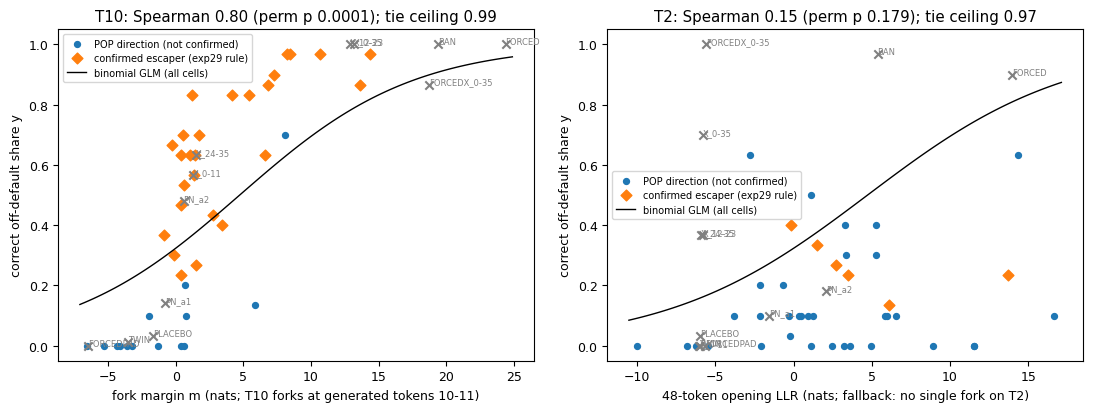

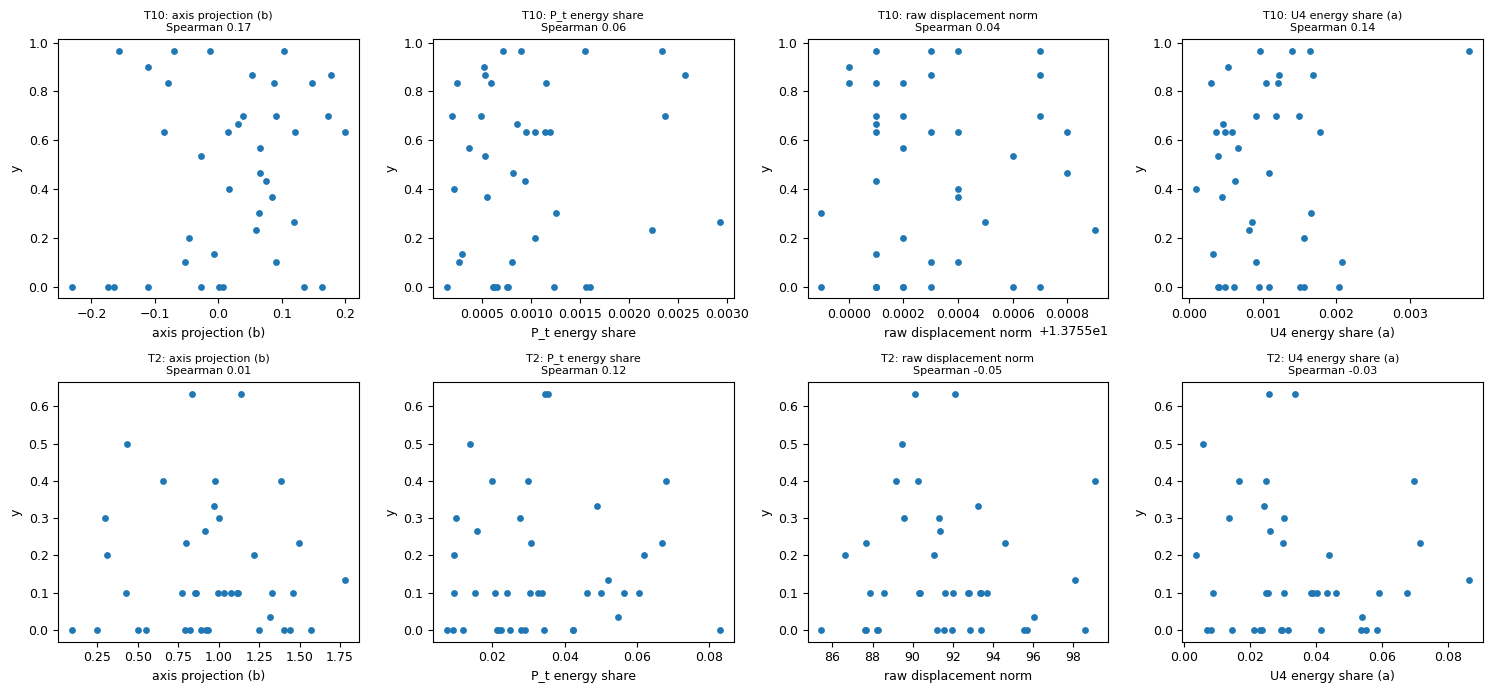

In [17]:
plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42, "ps.fonttype": 42})


def save(fig, name: str) -> None:
    fig.tight_layout()
    plt.show()          # notebook: shown inline (original: figures/{name}.png and .pdf)


def f2_f3() -> None:
    """figures7.f2_f3_f4 without F4 (the layer profile needs per-block projections)."""
    fa = {"F": res["F"], "cells": res["cells"]}      # original: read_json(RESULTS / "f_analysis.json")
    pa = {"P2": res["P2"]}                          # original: read_json(RESULTS / "p2_analysis.json")
    cal = fa["F"]["calibration"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    for ax, t in zip(axes, ("T10", "T2")):
        rows = fa["cells"][t]
        m = np.array([r["m"] for r in rows])
        y = np.array([r["y"] for r in rows])
        conf = np.array([r["confirmed"] for r in rows])
        ax.scatter(m[conf == 0], y[conf == 0], s=18, label="POP direction (not confirmed)")
        ax.scatter(m[conf == 1], y[conf == 1], s=30, marker="D", label="confirmed escaper (exp29 rule)")
        others = [c for c in cal["cells"] if c["cell"].startswith(t + "|") and "POP_" not in c["cell"]]
        for c in others:
            ax.scatter(c["m"], c["y"], marker="x", color="gray")
            ax.annotate(c["cell"].split("|")[1], (c["m"], c["y"]), fontsize=6, color="gray")
        xs = np.linspace(min(list(m) + [c["m"] for c in others]) - 0.5, max(list(m) + [c["m"] for c in others]) + 0.5,
                         100)
        ax.plot(xs, 1 / (1 + np.exp(-(cal["b0"] + cal["b1"] * xs))), "k-", lw=1, label="binomial GLM (all cells)")
        F = fa["F"][t]
        src = "fork margin" if t == "T10" else "llr48 (no single fork)"   # original: margin_source of the commit #3 twin
        ax.set_title(f"{t}: Spearman {F['rho']:.2f} (perm p {F['p_perm']:.3g}); tie ceiling {F['rho_max_ties']:.2f}")
        ax.set_xlabel("fork margin m (nats; T10 forks at generated tokens 10-11)" if "llr" not in src else
                      "48-token opening LLR (nats; fallback: no single fork on T2)")
        ax.set_ylabel("correct off-default share y")
        ax.legend(fontsize=7)
    save(fig, "F2_margin_vs_outcome")
    fig, axes = plt.subplots(2, 4, figsize=(15, 7))
    for row, t in enumerate(("T10", "T2")):
        rows = fa["cells"][t]
        y = np.array([r["y"] for r in rows])
        for ax, (k, nm) in zip(axes[row], (("b", "axis projection (b)"), ("pi_Pt", "P_t energy share"),
                                           ("norm", "raw displacement norm"), ("a_share", "U4 energy share (a)"))):
            x = np.array([r[k] for r in rows])
            ax.scatter(x, y, s=15)
            P = pa["P2"][t]
            rho = P["rho_b"] if k == "b" else P["competitors"][k]["rho"]
            ax.set_title(f"{t}: {nm}\nSpearman {rho:.2f}", fontsize=8)
            ax.set_xlabel(nm)
            ax.set_ylabel("y")
    save(fig, "F3_axis_vs_competitors")


f2_f3()

## 6. Stage `outputs` (CPU, re-run here): the placebos of the independent audit

`audit/rederive.py` re-derives the headline numbers with the standard library only (199 checks, 0 mismatches in the
recorded run). It also runs placebos that **must fail**:

- **Shuffled y.** The fork margin against randomly permuted outcomes must give a null Spearman (recorded median about 0.01 on T10).
- **Random axis.** A shuffled b must not track y.
- **Shuffled fork-token map (T10).** The q values are permuted across the mapped tokens of each fork. In the recorded run the median null rho was 0.22, but 18% of the 200 permutations reached the observed 0.80. With only 4 + 2 mapped tokens, every permutation that keeps a low q on the default tokens reproduces the effect. So the margin gets its power from **the probability of staying on the default fork tokens** (`' parent'`, `def find`), not from the exact q of the alternatives.

The loops below are the placebo part of `rederive.main()`. They are unchanged except for the inputs and the
draw counts from the config cell.

In [18]:
def audit_placebos() -> list[dict[str, Any]]:
    """Placebo part of audit/rederive.py main() (the stdlib spearman there equals stats7.spearman)."""
    checks = []
    fa = {"F": res["F"], "cells": res["cells"]}           # original: results/f_analysis.json
    for task in ("T10", "T2"):
        m, y, b = [], [], []
        for row in fa["cells"][task]:
            c = CELLS[f"{task}|POP_d{row['seed']}_a2.0"]      # original: c3[f"{task}|POP_d{row['seed']}_a2.0"]
            m.append(c["m"])
            b.append(c["b"])
            y.append(row["y"])                                # original: y re-derived from the exp29 label rows
        rnd = random.Random(7)
        null = []
        for _ in range(N_PLACEBO_Y):
            yy = y[:]
            rnd.shuffle(yy)
            null.append(spearman(m, yy))
        null = [v for v in null if v == v]
        checks.append({"name": f"placebo shuffled-y F {task}", "median_null_rho": sorted(null)[len(null) // 2],
                       "observed": spearman(m, y)})
        bb = b[:]
        rnd.shuffle(bb)
        checks.append({"name": f"placebo random axis P2 {task}", "rho_shuffled_b": spearman(bb, y),
                       "observed": spearman(b, y)})
    y10 = {r["seed"]: r["y"] for r in fa["cells"]["T10"]}
    m_re, yv = [], []
    for s, yy in sorted(y10.items()):
        mm = margin(f"POP_d{s}_a2.0", q_true)
        m_re.append(mm)
        yv.append(yy)
    rnd = random.Random(11)
    null = []
    for _ in range(N_PLACEBO_MAP):
        qs = []
        for q in q_true:
            keys = list(q)
            vals = [q[k] for k in keys]
            rnd.shuffle(vals)
            qs.append(dict(zip(keys, vals)))
        null.append(spearman([margin(f"POP_d{s}_a2.0", qs) for s in sorted(y10)], yv))
    null = sorted(v for v in null if v == v)
    checks.append({"name": "placebo shuffled fork token map (T10)", "observed": spearman(m_re, yv),
                   "null_median": null[len(null) // 2] if null else None,
                   "null_95pct": null[int(0.95 * len(null))] if null else None,
                   "share_null_ge_observed": sum(1 for v in null if v >= spearman(m_re, yv)) / max(1, len(null)),
                   "null": null})                         # notebook: the null draws are kept for the summary plot
    return checks


checks = audit_placebos()
for c in checks:
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in c.items() if k != "null"})

{'name': 'placebo shuffled-y F T10', 'median_null_rho': 0.01, 'observed': 0.804}
{'name': 'placebo random axis P2 T10', 'rho_shuffled_b': 0.059, 'observed': 0.173}
{'name': 'placebo shuffled-y F T2', 'median_null_rho': -0.005, 'observed': 0.149}
{'name': 'placebo random axis P2 T2', 'rho_shuffled_b': -0.004, 'observed': 0.015}
{'name': 'placebo shuffled fork token map (T10)', 'observed': 0.804, 'null_median': 0.224, 'null_95pct': 0.863, 'share_null_ge_observed': 0.18}


## 7. Summary: recomputed vs recorded

The table puts the numbers recomputed above beside the recorded values of the full run (`metadata.recorded` in the
demo data). With the original draw counts (`N_PERM = N_BOOT = 10000`, `N_CAL_SPLITS = 10`) and all 40 directions, every
committed number and both verdicts reproduce to the printed precision.

The demo data keeps the predictors as the dataset's 6-significant-digit strings. That preserves every rank except
one. All 40 T10 pushes have almost the same raw displacement norm (they are equal-dose pushes, 13.7549-13.7559), so
rounding leaves 11 distinct values. That competitor's Spearman therefore moves from 0.028 to 0.039 (last table row).

- **Left panel:** how well each predictor ranks the random directions on each task, against the tie ceiling and the committed thresholds.
- **Right panel:** the shuffled-token-map placebo from section 6.

quantity                                    recomputed    recorded
F  T10 Spearman(m, y)                           0.8039      0.8039
F  T10 permutation p                            0.0001      0.0001
F  T10 95% CI, low                              0.6170      0.6170
F  T10 95% CI, high                             0.9054      0.9054
F  T10 tie ceiling                              0.9929      0.9929
F  T10 AUC, confirmed escapers                  0.8104      0.8104
F  T2 Spearman(m, y) (LLR48 fallback)           0.1487      0.1487
F  T2 permutation p                             0.1787      0.1787
F  pooled within-task rho                       0.4798      0.4798
F  calibration, held-out MAE                    0.2523      0.2523
P2 T10 Spearman(b, y)                           0.1733      0.1733
P2 T10 permutation p                            0.1411      0.1411
P2 T2 Spearman(b, y)                            0.0149      0.0149
P2 T2 permutation p                             0.4580      0.

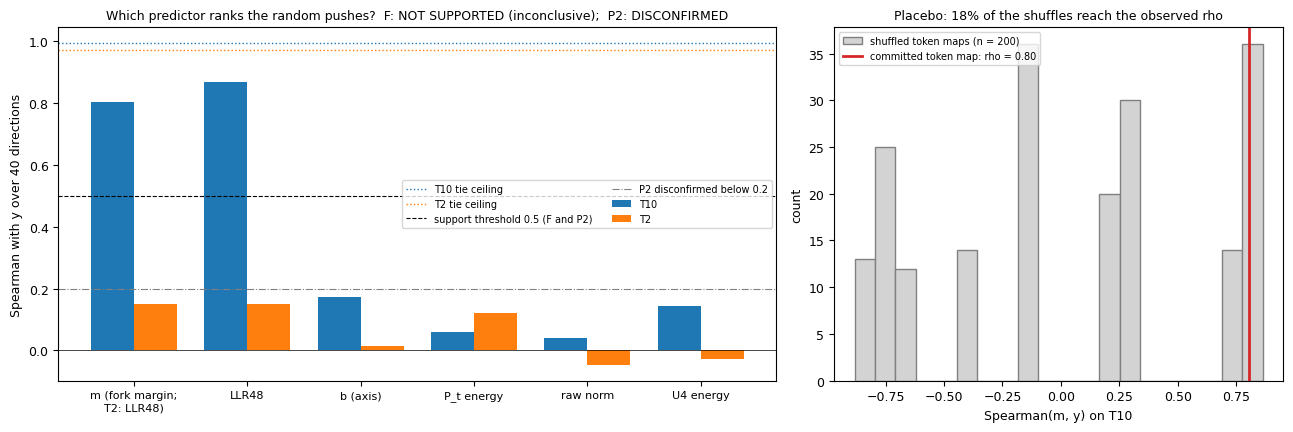

In [19]:
rec = data["metadata"]["recorded"]
rows = [("F  T10 Spearman(m, y)", res["F"]["T10"]["rho"], rec["F"]["T10"]["rho"]),
        ("F  T10 permutation p", res["F"]["T10"]["p_perm"], rec["F"]["T10"]["p_perm"]),
        ("F  T10 95% CI, low", res["F"]["T10"]["ci"][0], rec["F"]["T10"]["ci"][0]),
        ("F  T10 95% CI, high", res["F"]["T10"]["ci"][1], rec["F"]["T10"]["ci"][1]),
        ("F  T10 tie ceiling", res["F"]["T10"]["rho_max_ties"], rec["F"]["T10"]["rho_max_ties"]),
        ("F  T10 AUC, confirmed escapers", res["F"]["T10"]["auc_confirmed"], rec["F"]["T10"]["auc_confirmed"]),
        ("F  T2 Spearman(m, y) (LLR48 fallback)", res["F"]["T2"]["rho"], rec["F"]["T2"]["rho"]),
        ("F  T2 permutation p", res["F"]["T2"]["p_perm"], rec["F"]["T2"]["p_perm"]),
        ("F  pooled within-task rho", res["F"]["pooled"]["rho"], rec["F"]["pooled"]["rho"]),
        ("F  calibration, held-out MAE", res["F"]["calibration"]["mae_heldout_mean"],
         rec["F"]["calibration"]["mae_heldout_mean"]),
        ("P2 T10 Spearman(b, y)", res["P2"]["T10"]["rho_b"], rec["P2"]["T10"]["rho_b"]),
        ("P2 T10 permutation p", res["P2"]["T10"]["p_perm"], rec["P2"]["T10"]["p_perm"]),
        ("P2 T2 Spearman(b, y)", res["P2"]["T2"]["rho_b"], rec["P2"]["T2"]["rho_b"]),
        ("P2 T2 permutation p", res["P2"]["T2"]["p_perm"], rec["P2"]["T2"]["p_perm"]),
        ("Holm-adjusted p, F", res["verdicts"]["holm"]["F"], rec["verdicts"]["holm"]["F"]),
        ("Holm-adjusted p, P2", res["verdicts"]["holm"]["P2"], rec["verdicts"]["holm"]["P2"]),
        ("P2 T10 competitor raw norm (6-digit ties)", res["P2"]["T10"]["competitors"]["norm"]["rho"],
         rec["P2"]["T10"]["competitors"]["norm"]["rho"])]
print(f"{'quantity':42s} {'recomputed':>11s} {'recorded':>11s}")
for name, a, b_ in rows:
    print(f"{name:42s} {a:11.4f} {b_:11.4f}")
print(f"\nverdict F : {res['verdicts']['F']:30s} (recorded: {rec['verdicts']['F']})")
print(f"verdict P2: {res['verdicts']['P2']:30s} (recorded: {rec['verdicts']['P2']})")

# left: Spearman of every predictor with y, per task; right: the shuffled fork-token-map placebo on T10
preds = [("m (fork margin;\nT2: LLR48)", lambda t: res["F"][t]["rho"]),
         ("LLR48", lambda t: res["F"][t]["llr48"]["rho"]),
         ("b (axis)", lambda t: res["P2"][t]["rho_b"]),
         ("P_t energy", lambda t: res["P2"][t]["competitors"]["pi_Pt"]["rho"]),
         ("raw norm", lambda t: res["P2"][t]["competitors"]["norm"]["rho"]),
         ("U4 energy", lambda t: res["P2"][t]["competitors"]["a_share"]["rho"])]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.6, 1]})
xs = np.arange(len(preds))
for i, (t, col) in enumerate((("T10", "tab:blue"), ("T2", "tab:orange"))):
    ax1.bar(xs + (i - 0.5) * 0.38, [f(t) for _, f in preds], 0.38, color=col, label=t)
    ax1.axhline(res["F"][t]["rho_max_ties"], color=col, ls=":", lw=1, label=f"{t} tie ceiling")
ax1.axhline(THRESHOLDS["F"]["rho_each"], color="k", ls="--", lw=0.8, label="support threshold 0.5 (F and P2)")
ax1.axhline(THRESHOLDS["P2"]["disconfirm_rho"], color="gray", ls="-.", lw=0.8, label="P2 disconfirmed below 0.2")
ax1.axhline(0, color="k", lw=0.5)
ax1.set_xticks(xs)
ax1.set_xticklabels([n for n, _ in preds], fontsize=8)
ax1.set_ylabel(f"Spearman with y over {res['F']['T10']['n']} directions")
ax1.set_title(f"Which predictor ranks the random pushes?  F: {res['verdicts']['F']};  P2: {res['verdicts']['P2']}",
              fontsize=9)
ax1.legend(fontsize=7, ncol=2)
pl = checks[-1]
ax2.hist(pl["null"], bins=20, color="lightgray", edgecolor="gray", label=f"shuffled token maps (n = {len(pl['null'])})")
ax2.axvline(pl["observed"], color="tab:red", lw=2, label=f"committed token map: rho = {pl['observed']:.2f}")
ax2.set_xlabel("Spearman(m, y) on T10")
ax2.set_ylabel("count")
ax2.set_title(f"Placebo: {pl['share_null_ge_observed']:.0%} of the shuffles reach the observed rho", fontsize=9)
ax2.legend(fontsize=7)
plt.tight_layout()
plt.show()

## What the other stages found (recorded in the full run, not re-run here)

- **P2 is disconfirmed, and the axis is not the channel that random pushes use.** Clamping the axis component of every push at blocks L_ax-35 leaves 105 escapes, against 104 without the clamp (a random-direction clamp gives 106). The axis is not dormant: neutral prompts vary 220-400x more along it than along random directions.
- **The axis is still a sufficient control direction on T10.** A single-layer targeted push along it gives no escape at the committed doses s <= 1, but at s = 4 T10 switches to correct DFS on 29/30 slots, against 0/30 for a matched random direction. T2 shows no escape even at s = 8, and T03 is not axis-specific.
- **T03 prospective confirmation.** On 24 fresh, pre-committed directions, the opening margin predicts y with Spearman 0.60 (one-sided p 0.0014); the axis projection does not (0.22).
- **T1 in-manifold top-five push.** Pushes toward the survivor-region centroid give 0/300 non-top-five programs, all BFS. The geometry is Isomap/MDS/PCA of real block-18 activations of forced "implement X" prompts. The prompt top-five ban also stays inside the banned set.
- **Exploratory forced token.** Under the unchanged twin prompt, forcing `def dfs` at tokens 10-11 gives 30/30 correct DFS, and forcing a comment token gives 30/30 union-find. So the token that names the routine decides T10, while the effect of non-committal tokens depends on the cell.
- **Robustness.** All 40 directions were re-measured on the run's own GPU: their y correlates 0.95 (T10) and 0.93 (T2) with exp29, and the conclusions do not change. The stdlib audit made 199 checks with 0 mismatches.

**Limits.** One model; memorised LeetCode-style tasks; a sparse fork screen (the C3 power check detects a 0.4 jump only 54% of the time); AST-only labels for the 10-algorithm T1 catalogue.